# Checkpoint image codec trial

Select the existing `dip-project1` kernel. The next cell chooses a random Kodak image and the most recently modified `latest.pt` checkpoint under `DIP_RUNS_ROOT` or the repository's `runs` folder. Rerun it to choose another image; edit its paths to select specific inputs. The checkpoint is loaded on CPU and is not modified.

Kodak is reserved for final evaluation, not training or model selection.

In [1]:
import os
import random
import sys
from pathlib import Path

if os.name == "nt":
    library_bin = Path(sys.prefix) / "Library" / "bin"
    path_entries = os.environ.get("PATH", "").split(os.pathsep)
    if library_bin.is_dir() and os.path.normcase(os.path.normpath(path_entries[0])) != os.path.normcase(str(library_bin)):
        os.environ["PATH"] = str(library_bin) + os.pathsep + os.environ.get("PATH", "")

current = Path.cwd().resolve()
REPOSITORY = next(
    (path for path in (current, *current.parents) if (path / "src" / "settings.py").is_file()),
    None,
)
if REPOSITORY is None:
    raise RuntimeError("Open this notebook from the project or set the working directory to the project root")
sys.path.insert(0, str(REPOSITORY / "src"))

from data.paths import KODAK_DIR

RUNS_ROOT = Path(os.environ.get("DIP_RUNS_ROOT", REPOSITORY / "runs"))
checkpoints = [path for path in RUNS_ROOT.glob("*/checkpoints/latest.pt") if path.is_file()]
if not checkpoints:
    raise FileNotFoundError(f"No run checkpoint found under {RUNS_ROOT}")
CHECKPOINT_PATH = max(checkpoints, key=lambda path: path.stat().st_mtime_ns)
RUN_DIR = CHECKPOINT_PATH.parent.parent

image_extensions = {".bmp", ".jpeg", ".jpg", ".png", ".tif", ".tiff", ".webp"}
images = sorted(path for path in KODAK_DIR.rglob("*") if path.is_file() and path.suffix.lower() in image_extensions)
if not images:
    raise FileNotFoundError(f"No Kodak images found under {KODAK_DIR}; check DIP_DATA_ROOT")
IMAGE_PATH = random.choice(images)
print(f"Selected checkpoint: {CHECKPOINT_PATH}")
print(f"Selected Kodak image: {IMAGE_PATH}")

Selected checkpoint: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\runs\pilot_64-20261117-212818\checkpoints\latest.pt
Selected Kodak image: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\data\kodak\kodim20.png


## Load and inspect

The image is converted to RGB; original dimensions are preserved.

c:\ProgramData\miniconda3\envs\dip-project1\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Checkpoint: C:\Users\abdelazm\OneDrive - STMicroelectronics\Myspace\master\Digital_Image\git\Digial_Image_Processing_Project_CSE681\runs\pilot_64-20261117-212818\checkpoints\latest.pt
Model: N=64, M=64
Image: 768 x 512


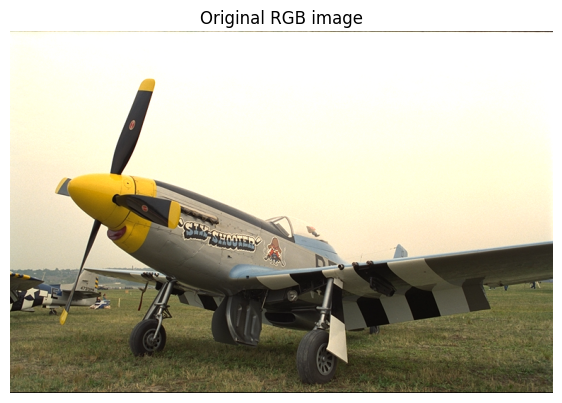

In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from codec.inference import (
    load_codec, encode_image, decode_image, image_metrics, export_codec_checkpoint,
)

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Select a run with a checkpoint: {CHECKPOINT_PATH}")
if not IMAGE_PATH.is_file():
    raise FileNotFoundError(f"Select an existing image: {IMAGE_PATH}")

model, settings = load_codec(CHECKPOINT_PATH)
with Image.open(IMAGE_PATH) as source:
    original = source.convert("RGB")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Model: N={settings.num_channels}, M={settings.latent_channels}")
print(f"Image: {original.width} x {original.height}")
plt.figure(figsize=(7, 7))
plt.imshow(original)
plt.title("Original RGB image")
plt.axis("off")
plt.show()

## Encode and decode

Actual BPP counts the header and both encoded streams, divided by the original image pixel count; it assumes the decoder already has the model and does not include checkpoint size. PSNR compares 8-bit RGB pixels after decoding; this is a single-image trial, not a dataset benchmark.

Encoded size: 19,780 bytes
Actual coded BPP: 0.4024
RGB PSNR: 20.40 dB


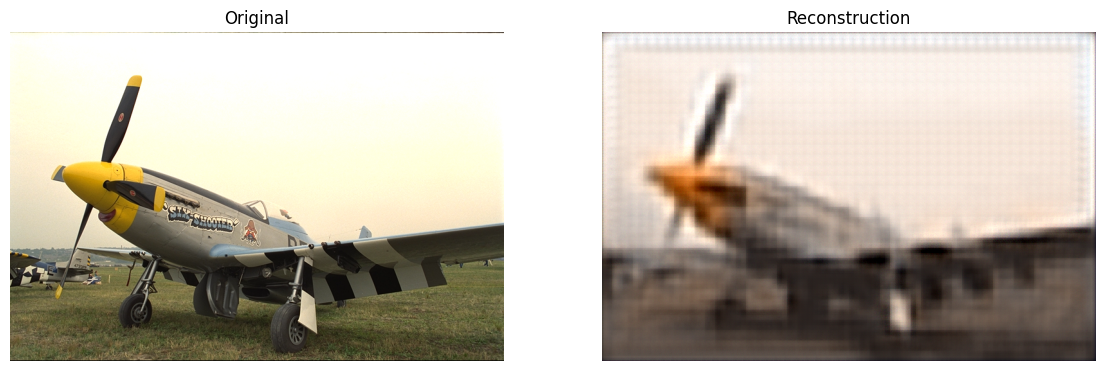

In [3]:
bitstream = encode_image(model, original)
reconstruction = decode_image(model, bitstream)
metrics = image_metrics(original, reconstruction, bitstream)
print(f"Encoded size: {metrics['bytes']:,} bytes")
print(f"Actual coded BPP: {metrics['bpp']:.4f}")
print(f"RGB PSNR: {metrics['psnr_db']:.2f} dB")

figure, axes = plt.subplots(1, 2, figsize=(14, 7))
for axis, image, title in zip(axes, (original, reconstruction), ("Original", "Reconstruction")):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
plt.show()

## Optional: save trial outputs

Set `OUTPUT_DIR` below and run the cell only if you want to save the codec checkpoint, bitstream and reconstruction. The output folder must not already exist. These files are local trial artifacts. Decode the bitstream with the accompanying codec checkpoint.

In [ ]:
import hashlib
import json

OUTPUT_DIR = REPOSITORY / "results" / "codec_trial"
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
export_codec_checkpoint(model, settings, OUTPUT_DIR / "codec.pt")
(OUTPUT_DIR / "image.shc").write_bytes(bitstream)
reconstruction.save(OUTPUT_DIR / "reconstruction.png")
metadata = {
    "source_checkpoint": str(CHECKPOINT_PATH),
    "source_checkpoint_sha256": hashlib.sha256(CHECKPOINT_PATH.read_bytes()).hexdigest(),
    "image": str(IMAGE_PATH),
    "metrics": metrics,
}
(OUTPUT_DIR / "trial.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved to {OUTPUT_DIR}")